In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv("../data/cleaned/financial_fraud_clean.csv")

In [8]:
df["Transaction_Date"] = pd.to_datetime(df["Transaction_Date"])

In [9]:
df.head()

,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Merchant_Category,Payment_Method,Device_Type,Location,Is_International,Previous_Transactions,Average_Spend,Account_Age_Days,Suspicious_Keyword,Fraudulent
0,T100000,CUST3252,2023-10-04 07:45:00,37.54,Travel,PayPal,POS,Bengaluru,0,94,417.40,1492,No,0
1,T100001,CUST1630,2023-09-26 08:29:00,240.81,Utilities,PayPal,Mobile,Bengaluru,0,76,335.47,66,No,0
2,T100002,CUST7852,2023-07-18 15:54:00,105.34,Entertainment,Debit Card,Mobile,Bengaluru,0,60,432.03,216,No,0
3,T100003,CUST4892,2023-10-16 17:10:00,73.04,Utilities,NetBanking,Desktop,Kolkata,0,68,488.30,449,No,0
4,T100004,CUST8831,2023-09-09 00:46:00,13.57,Utilities,Credit Card,Desktop,Bengaluru,0,57,437.03,754,No,0


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Transaction_ID         5000 non-null   object        
 1   Customer_ID            5000 non-null   object        
 2   Transaction_Date       5000 non-null   datetime64[ns]
 3   Transaction_Amount     5000 non-null   float64       
 4   Merchant_Category      5000 non-null   object        
 5   Payment_Method         5000 non-null   object        
 6   Device_Type            5000 non-null   object        
 7   Location               5000 non-null   object        
 8   Is_International       5000 non-null   int64         
 9   Previous_Transactions  5000 non-null   int64         
 10  Average_Spend          5000 non-null   float64       
 11  Account_Age_Days       5000 non-null   int64         
 12  Suspicious_Keyword     5000 non-null   object        
 13  Fra

In [11]:
df.describe()

,Transaction_Date,Transaction_Amount,Is_International,Previous_Transactions,Average_Spend,Account_Age_Days,Fraudulent
count,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2023-07-30 02:54:51.744000,79.180664,0.088200,99.414000,258.377132,1011.158200,0.096400
min,2023-01-01 02:16:00,0.000000,0.000000,1.000000,10.010000,30.000000,0.000000
25%,2023-04-18 23:04:15,22.365000,0.000000,50.000000,138.772500,530.000000,0.000000
50%,2023-07-31 02:27:00,55.455000,0.000000,100.000000,261.810000,1012.500000,0.000000
75%,2023-11-08 12:25:15,110.297500,0.000000,148.000000,378.525000,1496.000000,0.000000
max,2024-02-21 15:34:00,653.800000,1.000000,199.000000,499.990000,1999.000000,1.000000
std,NaN,78.964045,0.283614,57.022968,140.230639,568.633834,0.295169


In [12]:
df["Fraudulent"].value_counts()

Fraudulent
0    4518
1     482
Name: count, dtype: int64

In [13]:
df["Fraudulent"].value_counts(normalize=True) * 100

Fraudulent
0    90.36
1     9.64
Name: proportion, dtype: float64

In [14]:
df["Fraud_Status"] = df["Fraudulent"].map({
    0: "Non-Fraud",
    1: "Fraud"
})

In [15]:
df["Fraud_Status"].value_counts()

Fraud_Status
Non-Fraud    4518
Fraud         482
Name: count, dtype: int64

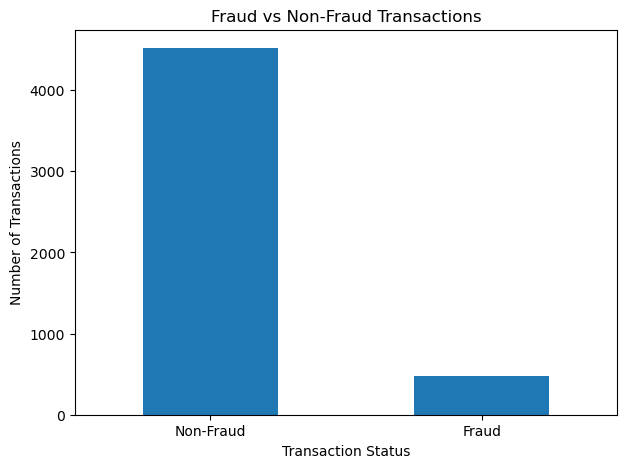

In [16]:
df["Fraud_Status"].value_counts().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Transaction Status")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)

plt.show()

In [17]:
df["Transaction_Amount"].describe()

count    5000.000000
mean       79.180664
std        78.964045
min         0.000000
25%        22.365000
50%        55.455000
75%       110.297500
max       653.800000
Name: Transaction_Amount, dtype: float64

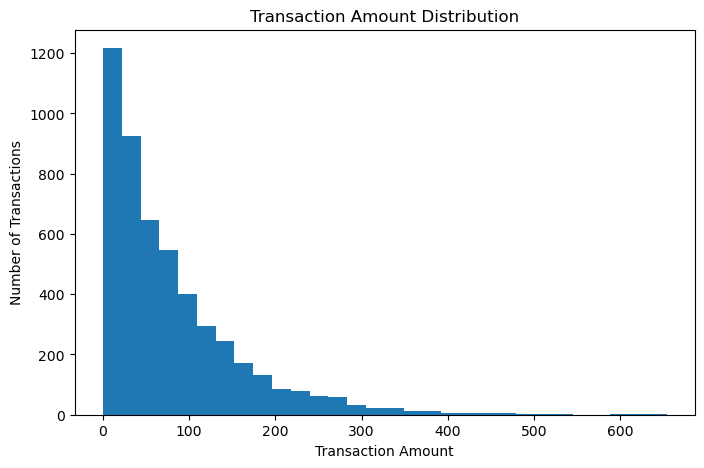

In [18]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["Transaction_Amount"],
    bins=30
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.show()

In [19]:
df.groupby("Fraud_Status")["Transaction_Amount"].mean()

Fraud_Status
Fraud        81.993693
Non-Fraud    78.880558
Name: Transaction_Amount, dtype: float64

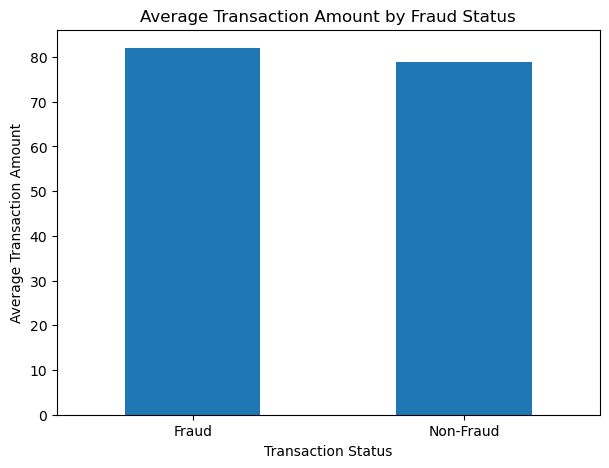

In [21]:
df.groupby("Fraud_Status")["Transaction_Amount"].mean().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Average Transaction Amount by Fraud Status")
plt.xlabel("Transaction Status")
plt.ylabel("Average Transaction Amount")
plt.xticks(rotation=0)

plt.show()

In [22]:
merchant_fraud = pd.crosstab(
    df["Merchant_Category"],
    df["Fraud_Status"]
)

merchant_fraud

Fraud_Status,Fraud,Non-Fraud
Merchant_Category,,
Electronics,49,601
Entertainment,72,558
Fashion,62,546
Food,74,610
Grocery,58,571
Health,61,545
Travel,56,543
Utilities,50,544


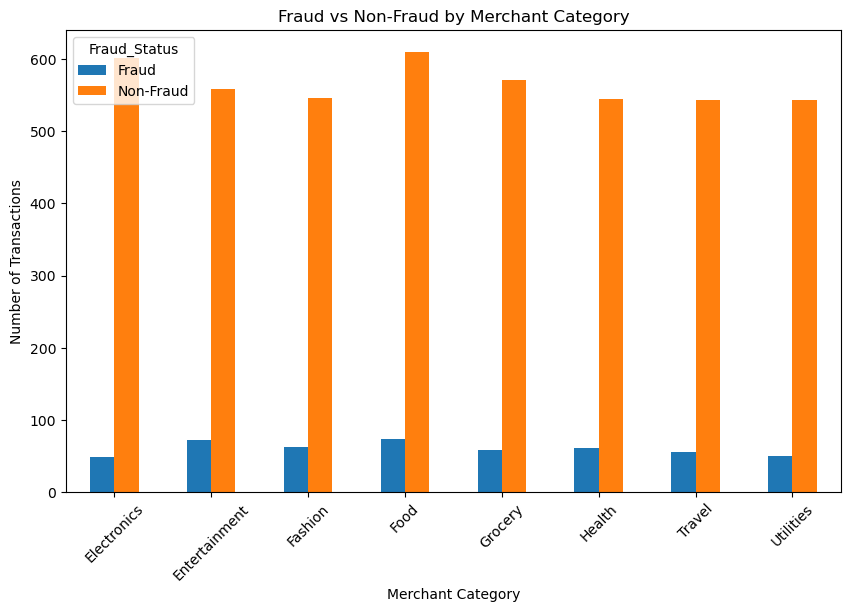

In [23]:
merchant_fraud.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Fraud vs Non-Fraud by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)

plt.show()

In [24]:
payment_fraud = pd.crosstab(
    df["Payment_Method"],
    df["Fraud_Status"]
)

payment_fraud

Fraud_Status,Fraud,Non-Fraud
Payment_Method,,
Credit Card,96,876
Debit Card,103,905
NetBanking,85,952
PayPal,98,924
UPI,100,861


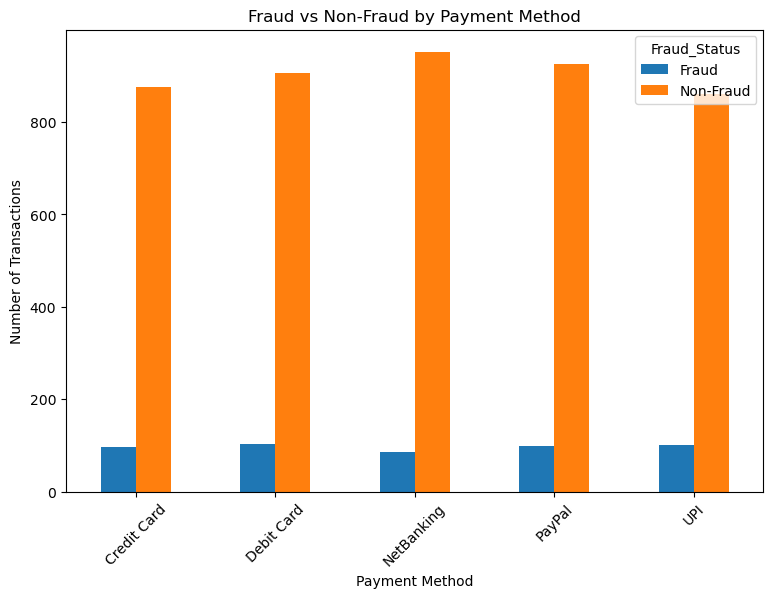

In [25]:
payment_fraud.plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("Fraud vs Non-Fraud by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)

plt.show()

In [26]:
device_fraud = pd.crosstab(
    df["Device_Type"],
    df["Fraud_Status"]
)

device_fraud

Fraud_Status,Fraud,Non-Fraud
Device_Type,,
Desktop,172,1507
Mobile,151,1497
POS,159,1514


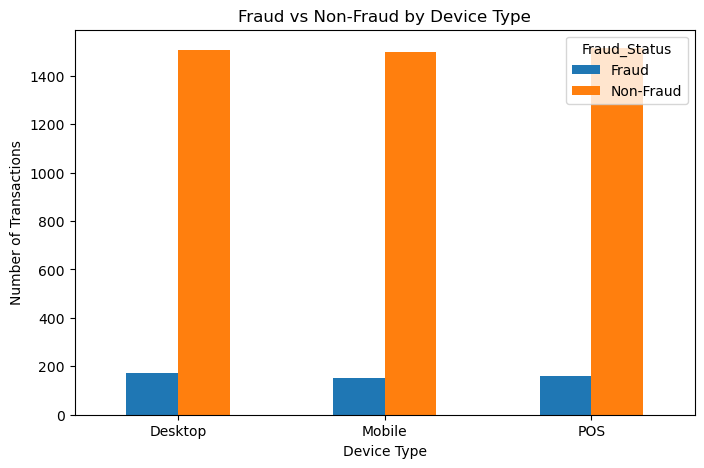

In [27]:
device_fraud.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Fraud vs Non-Fraud by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)

plt.show()

In [28]:
location_fraud = pd.crosstab(
    df["Location"],
    df["Fraud_Status"]
)

location_fraud

Fraud_Status,Fraud,Non-Fraud
Location,,
Bengaluru,71,615
Chennai,69,586
Delhi,65,693
Hyderabad,64,661
Kolkata,73,640
Mumbai,78,663
Pune,62,660


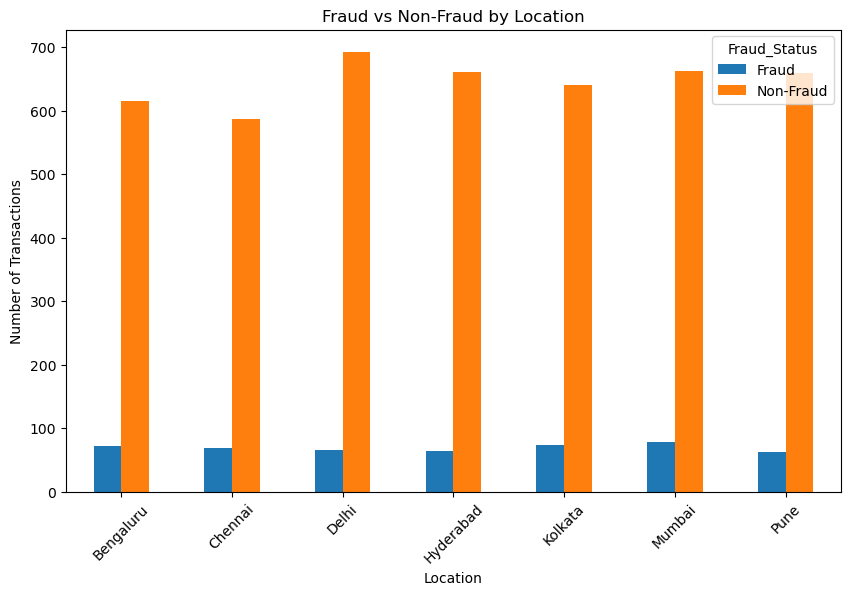

In [29]:
location_fraud.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Fraud vs Non-Fraud by Location")
plt.xlabel("Location")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)

plt.show()

In [30]:
df["International_Status"] = df["Is_International"].map({
    0: "Domestic",
    1: "International"
})

In [31]:
international_fraud = pd.crosstab(
    df["International_Status"],
    df["Fraud_Status"]
)

international_fraud

Fraud_Status,Fraud,Non-Fraud
International_Status,,
Domestic,319,4240
International,163,278


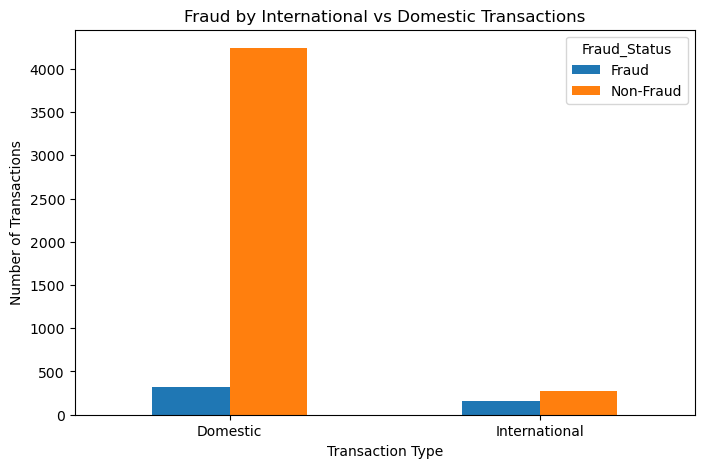

In [32]:
international_fraud.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Fraud by International vs Domestic Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)

plt.show()

In [33]:
keyword_fraud = pd.crosstab(
    df["Suspicious_Keyword"],
    df["Fraud_Status"]
)

keyword_fraud

Fraud_Status,Fraud,Non-Fraud
Suspicious_Keyword,,
No,359,4381
Yes,123,137


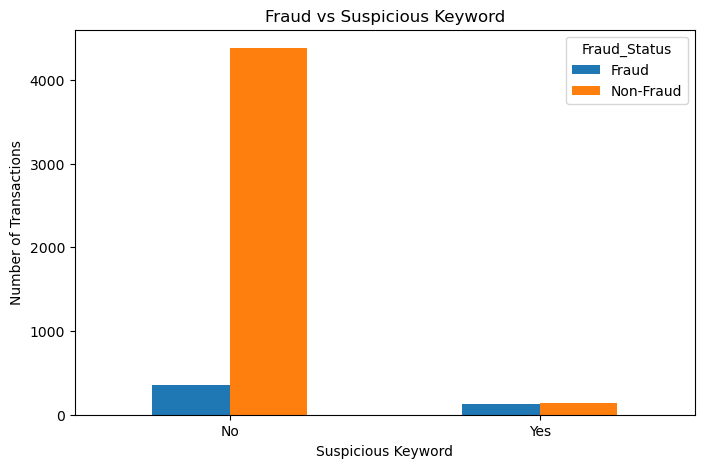

In [34]:
keyword_fraud.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Fraud vs Suspicious Keyword")
plt.xlabel("Suspicious Keyword")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)

plt.show()

In [35]:
df.groupby("Fraud_Status")["Previous_Transactions"].mean()

Fraud_Status
Fraud        96.856846
Non-Fraud    99.686808
Name: Previous_Transactions, dtype: float64

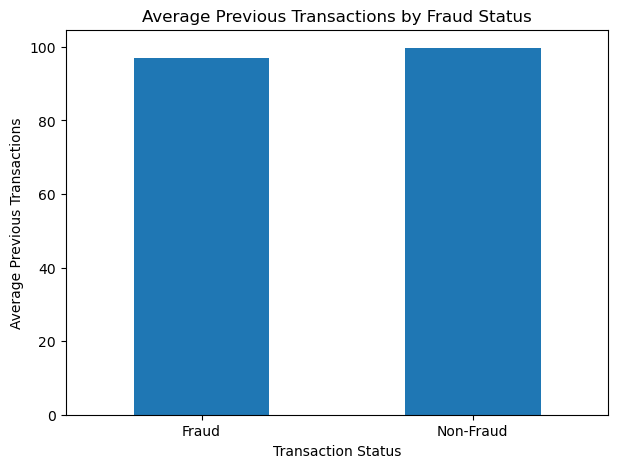

In [36]:
df.groupby("Fraud_Status")["Previous_Transactions"].mean().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Average Previous Transactions by Fraud Status")
plt.xlabel("Transaction Status")
plt.ylabel("Average Previous Transactions")
plt.xticks(rotation=0)

plt.show()

In [37]:
df.groupby("Fraud_Status")["Average_Spend"].mean()

Fraud_Status
Fraud        258.855249
Non-Fraud    258.326124
Name: Average_Spend, dtype: float64

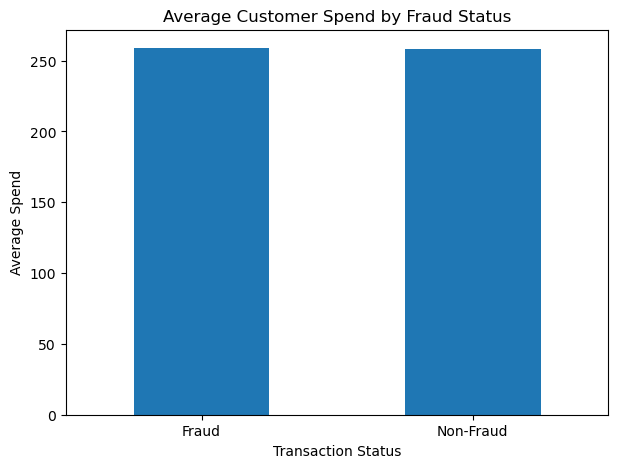

In [38]:
df.groupby("Fraud_Status")["Average_Spend"].mean().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Average Customer Spend by Fraud Status")
plt.xlabel("Transaction Status")
plt.ylabel("Average Spend")
plt.xticks(rotation=0)

plt.show()

In [39]:
Account_Age = df.groupby("Fraud_Status")["Account_Age_Days"].mean()

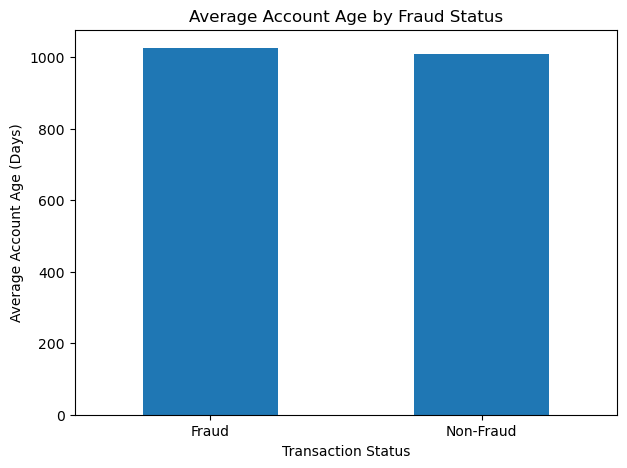

In [40]:
Account_Age.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Average Account Age by Fraud Status")
plt.xlabel("Transaction Status")
plt.ylabel("Average Account Age (Days)")
plt.xticks(rotation=0)

plt.show()

In [44]:
##Transaction Time Analysis

In [41]:
df["Transaction_Hour"] = df["Transaction_Date"].dt.hour

In [42]:
hourly_fraud = df.groupby(
    "Transaction_Hour"
)["Fraudulent"].sum()

hourly_fraud

Transaction_Hour
0     57
1     48
2     44
3     54
4     46
5     64
6     17
7      7
8     10
9     11
10     6
11    10
12    11
13    13
14     7
15     8
16    10
17     5
18     8
19    10
20     6
21    11
22     9
23    10
Name: Fraudulent, dtype: int64

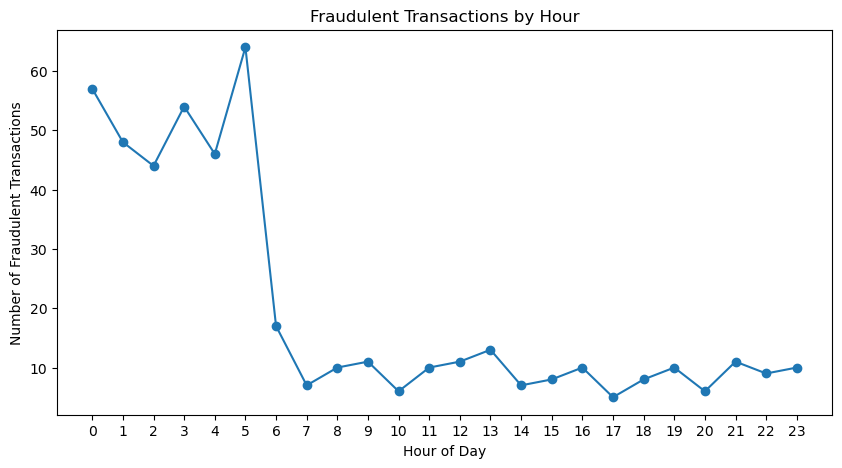

In [43]:
hourly_fraud.plot(
    kind="line",
    figsize=(10, 5),
    marker="o"
)

plt.title("Fraudulent Transactions by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Fraudulent Transactions")
plt.xticks(range(24))

plt.show()

In [46]:
##Monthly Fraud Analysis

In [47]:
df["Transaction_Month"] = df["Transaction_Date"].dt.month

In [48]:
monthly_fraud = df.groupby(
    "Transaction_Month"
)["Fraudulent"].sum()

monthly_fraud

Transaction_Month
1     71
2     53
3     36
4     36
5     31
6     30
7     40
8     32
9     40
10    51
11    31
12    31
Name: Fraudulent, dtype: int64

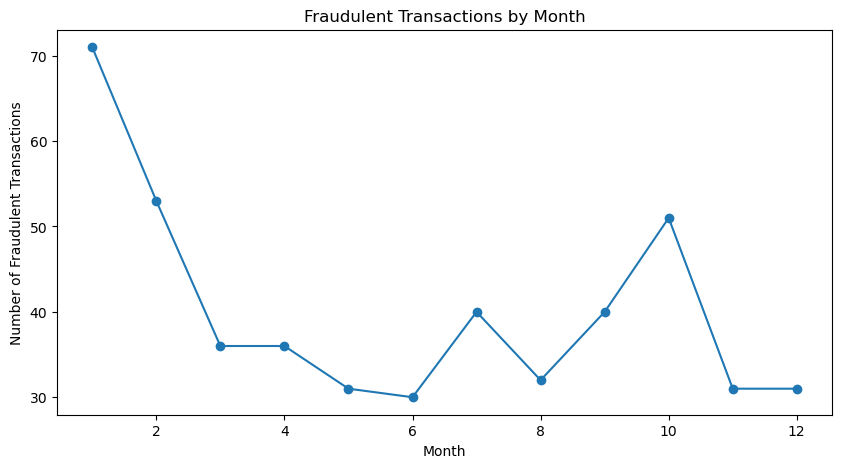

In [49]:
monthly_fraud.plot(
    kind="line",
    figsize=(10, 5),
    marker="o"
)

plt.title("Fraudulent Transactions by Month")
plt.xlabel("Month")
plt.ylabel("Number of Fraudulent Transactions")

plt.show()

In [50]:
##Numerical Correlation Analysis

In [51]:
numerical_columns = [
    "Transaction_Amount",
    "Is_International",
    "Previous_Transactions",
    "Average_Spend",
    "Account_Age_Days",
    "Fraudulent"
]

correlation = df[numerical_columns].corr()

correlation

,Transaction_Amount,Is_International,Previous_Transactions,Average_Spend,Account_Age_Days,Fraudulent
Transaction_Amount,1.000000,-0.004628,-0.011386,0.025404,0.003312,0.011637
Is_International,-0.004628,1.000000,-0.006254,0.019686,0.005640,0.287913
Previous_Transactions,-0.011386,-0.006254,1.000000,-0.016861,-0.000748,-0.014649
Average_Spend,0.025404,0.019686,-0.016861,1.000000,-0.003470,0.001114
Account_Age_Days,0.003312,0.005640,-0.000748,-0.003470,1.000000,0.008563
Fraudulent,0.011637,0.287913,-0.014649,0.001114,0.008563,1.000000


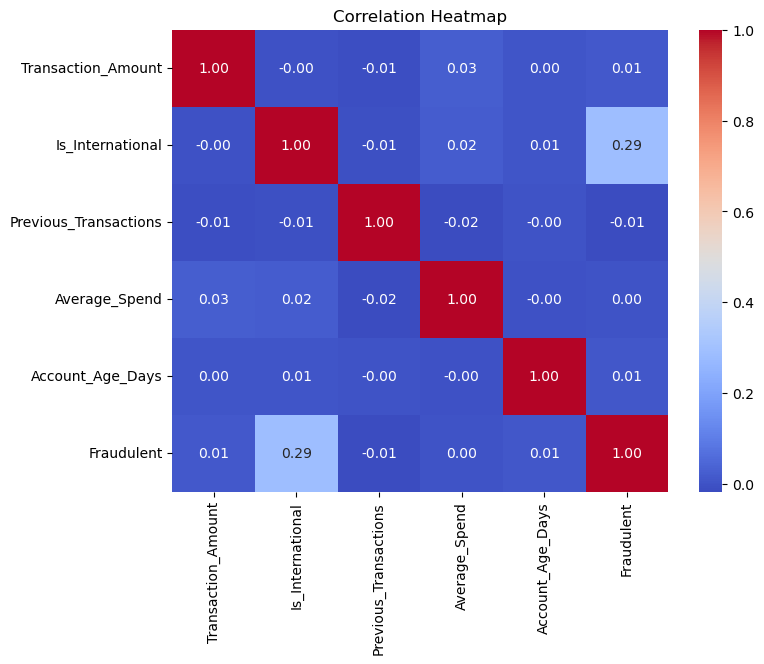

In [55]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [56]:
print("Total Transactions:", len(df))
print("Fraudulent Transactions:", df["Fraudulent"].sum())
print(
    "Non-Fraudulent Transactions:",
    (df["Fraudulent"] == 0).sum()
)
print(
    "Fraud Rate:",
    round(df["Fraudulent"].mean() * 100, 2),
    "%"
)

Total Transactions: 5000
Fraudulent Transactions: 482
Non-Fraudulent Transactions: 4518
Fraud Rate: 9.64 %
